In [ ]:
# import basic libraries

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

This document is used to display data visualization charts, calculate rolling statistics (rolling mean/SD) to check for drift, and compute basic statistical metrics for each factor ( mean, median, max value, min. value, and SD). Lastly, assess the presence of trends and seasonality.

The data in the ```final_monthly``` folder has been standardized for timestamps and cleaned; This notebook will double-check these cleanned data.

此文件用于展示数据可视化图表，计算滚动统计量（例如rolling mean/std）用于检查漂移，计算各个因子的基本统计数据（包括均值，中位数，最大值，最小值，标准差）。最后，判断是否包含趋势与季节性等走势。

```final_monthly```文件夹内的数据已经进行了时间戳统一和数据清洗，下面将检查数据是否可以直接使用。

In [ ]:
# dataset file path

DATASET_PATH = Path("data/final_monthly")
if not DATASET_PATH.is_dir():
    DATASET_PATH = Path("../data/final_monthly")
dataset_name_list = [
    "base_money_log_change_monthly.csv",
    "current_account_balance_annual_change_pp_monthly.csv",
    "food_imports_log_change_monthly.csv",
    "fuel_imports_log_change_monthly.csv",
    "fx_reserves_log_change_monthly.csv",
    "general_government_gross_debt_annual_change_pp_monthly.csv",
    "iron_ore_exports_log_change_monthly.csv",
    "NO_FILL_iron_ore_exports_log_change_monthly.csv",
    "USDSLE_monthly.csv"
]

默认使用2012—2024年训练期，每个CSV可视化图表包含原序列及12个月滚动均值、滚动标准差、去除线性斜率后的月份均值三个子图。

汇总表中，`screen_pass=True`表示本轮未检出设定范围内的信号，可继续ADF/KPSS检验；`False`表示存在需要核查的信号或样本缺口；`<NA>`表示本方法不适用或数据不足。任何结果都不等于证明数据平稳。p值小于0.05才标记趋势/季节性信号；滚动均值漂移分数达到1.0、滚动标准差比值达到2.0则提示核查。这两个滚动阈值是可调整的经验筛查标准，并非通用统计临界值。

存在中间缺失时，回归筛查仅使用最长连续区间，并在表中列明。其他月份没有被该回归检验覆盖。**年度变化逐月重复的两条序列仅展示描述性滚动图。**

The fixed screen uses the **2012-01 to 2024-12 training period**. The held-out period does not determine transformations. Each figure contains three diagnostic panels; policy dummies are excluded.

- Rolling mean and sample SD use **12 complete consecutive months**. Missing observations remain void.
- The regression uses an intercept, linear time and 11 calendar-month indicators. The trend null is zero time slope; the seasonal null is that all month effects are zero. HAC covariance uses 12 lags; Holm adjustment covers all trend/seasonal tests. Adjusted **p < 0.05 flags a signal**; larger p does not prove absence.
- Mean drift score = `(90th - 10th percentile of rolling means) / sample SD`. Flag at **1.0 or above**.
- SD ratio = `90th / 10th percentile of rolling SD`. Flag at **2.0 or above**. Zero lower SD with positive upper SD is an infinite ratio.
- The two rolling limits are **adjustable exploratory thresholds**, not universal statistical critical values. Scores use the same interval as the regression tests.
- For an internal gap, tests use the **longest complete interval**, reported in the results. An incomplete training interval cannot receive an overall pass. Annual changes repeated monthly have descriptive rolling plots only and no monthly inference.

`screen_pass=True` means only that this limited screen found no signals and ADF can be the next step.


In [6]:
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

# Select settings before examining the held-out forecast period.
SCREEN_START = "2012-01-31"
SCREEN_END = "2024-12-31"
ROLLING_WINDOW = 12
MIN_MONTHS = 36
HAC_LAGS = 12
ALPHA = 0.05
# Exploratory effect-size thresholds, NOT statistical critical values.
MEAN_DRIFT_LIMIT = 1.0
STD_RATIO_LIMIT = 2.0


In [7]:
def prepare_monthly(file_path):
    # The first physical column is the date; only the next column is data.
    frame = pd.read_csv(file_path, usecols=[0, 1], index_col=0, parse_dates=[0])
    values = pd.to_numeric(frame.iloc[:, 0], errors="raise").sort_index()
    if values.index.hasnans or values.index.has_duplicates:
        raise ValueError(f"Invalid/duplicate dates: {file_path.name}")
    if not values.index.is_month_end.all():
        raise ValueError(f"Expected month-end dates: {file_path.name}")
    if np.isinf(values.to_numpy(dtype=float)).any():
        raise ValueError(f"Infinite values: {file_path.name}")
    calendar = pd.date_range(SCREEN_START, SCREEN_END, freq="ME")
    return values.reindex(calendar).rename(frame.columns[0])


def longest_complete_segment(values):
    # Never join observations across a missing calendar month.
    groups = values.isna().cumsum()
    segments = [part.dropna() for _, part in values.groupby(groups) if part.notna().any()]
    return max(segments, key=len) if segments else values.iloc[:0]


def screen_series(values, annual_repeated=False):
    rolling = pd.DataFrame({
        "mean": values.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean(),
        "std": values.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std(ddof=1),
    })
    segment = longest_complete_segment(values)
    row = {
        "variable": values.name,
        "valid_months": int(values.notna().sum()),
        "missing_months": int(values.isna().sum()),
        "screen_start": segment.index.min() if len(segment) else pd.NaT,
        "screen_end": segment.index.max() if len(segment) else pd.NaT,
        "screen_n": len(segment),
        "trend_per_year": np.nan,
        "trend_p": np.nan,
        "seasonality_p": np.nan,
        "mean_drift_score": np.nan,
        "std_ratio": np.nan,
        "applicability": "monthly",
        "sample_note": "full training interval",
    }
    if annual_repeated:
        row["applicability"] = "annual values repeated monthly: monthly screen not applicable"
        return row, rolling, segment, None
    if len(segment) != len(values):
        row["sample_note"] = "longest complete interval only; other months not assessed by tests"
    if len(segment) < MIN_MONTHS:
        row["applicability"] = "insufficient consecutive months"
        return row, rolling, segment, None
    scale = segment.std(ddof=1)
    if not np.isfinite(scale) or scale == 0:
        row["applicability"] = "constant series: inference not applicable"
        return row, rolling, segment, None

    # Joint model: intercept + time in years + calendar-month indicators.
    # HAC allows short-run serial correlation/heteroskedasticity, not unit roots.
    design = pd.DataFrame({"const": 1.0, "time_years": np.arange(len(segment)) / 12.0}, index=segment.index)
    months = pd.Series(segment.index.month, index=segment.index)
    dummies = pd.get_dummies(months, prefix="month", drop_first=True, dtype=float)
    design = pd.concat([design, dummies], axis=1)
    fit = sm.OLS(segment, design).fit(
        cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS, "use_correction": True}
    )
    restrictions = np.zeros((len(dummies.columns), len(design.columns)))
    restrictions[:, 2:] = np.eye(len(dummies.columns))
    seasonal_test = fit.wald_test(restrictions, use_f=False, scalar=True)
    row["trend_per_year"] = float(fit.params["time_years"])
    row["trend_p"] = float(fit.pvalues["time_years"])
    row["seasonality_p"] = float(seasonal_test.pvalue)

    # Quantile ranges reduce sensitivity to a single extreme rolling window.
    # Both rolling scores refer to the SAME interval as the regression tests.
    segment_roll = rolling.loc[segment.index].dropna()
    q_mean = segment_roll["mean"].quantile([0.1, 0.9])
    q_std = segment_roll["std"].quantile([0.1, 0.9])
    row["mean_drift_score"] = float((q_mean.loc[0.9] - q_mean.loc[0.1]) / scale)
    low, high = float(q_std.loc[0.1]), float(q_std.loc[0.9])
    row["std_ratio"] = high / low if low > 0 else (np.inf if high > 0 else 1.0)
    trend = fit.params["const"] + fit.params["time_years"] * design["time_years"]
    # Remove just the slope when displaying the calendar-month pattern.
    detrended = segment - fit.params["time_years"] * design["time_years"]
    return row, rolling, segment, (trend, detrended)


def plot_screen(values, row, rolling, segment, fitted):
    fig, axes = plt.subplots(3, 1, figsize=(12, 9))
    values.plot(ax=axes[0], label="Observed", linewidth=0.9)
    rolling["mean"].plot(ax=axes[0], label=f"{ROLLING_WINDOW}-month rolling mean", linewidth=1.6)
    if fitted is not None:
        fitted[0].plot(ax=axes[0], label="Linear trend (base month)", linestyle="--")
    axes[0].set_title(f"{values.name} | {SCREEN_START[:7]} to {SCREEN_END[:7]}")
    axes[0].legend()
    rolling["std"].plot(ax=axes[1], label=f"{ROLLING_WINDOW}-month rolling SD", color="tab:orange")
    axes[1].legend()
    if fitted is not None:
        pattern = fitted[1].groupby(fitted[1].index.month).mean().reindex(range(1, 13))
        axes[2].plot(pattern.index, pattern.values, marker="o")
        axes[2].set_xticks(range(1, 13))
        axes[2].set_xlabel("Calendar month")
        axes[2].set_title("Mean by calendar month after removing the linear slope (screen interval)")
    else:
        axes[2].text(0.5, 0.5, row["applicability"], ha="center", va="center", wrap=True, transform=axes[2].transAxes)
        axes[2].set_axis_off()
    for ax in axes[:2]:
        ax.set_xlabel("Date")
    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()
    plt.close(fig)



base_money_log_change_monthly | training-period descriptive statistics
count    156.000000
mean       1.619169
std        5.251542
min      -10.009546
25%       -2.042102
50%        0.740436
75%        3.914659
max       17.374244
Name: base_money_log_change_monthly, dtype: float64


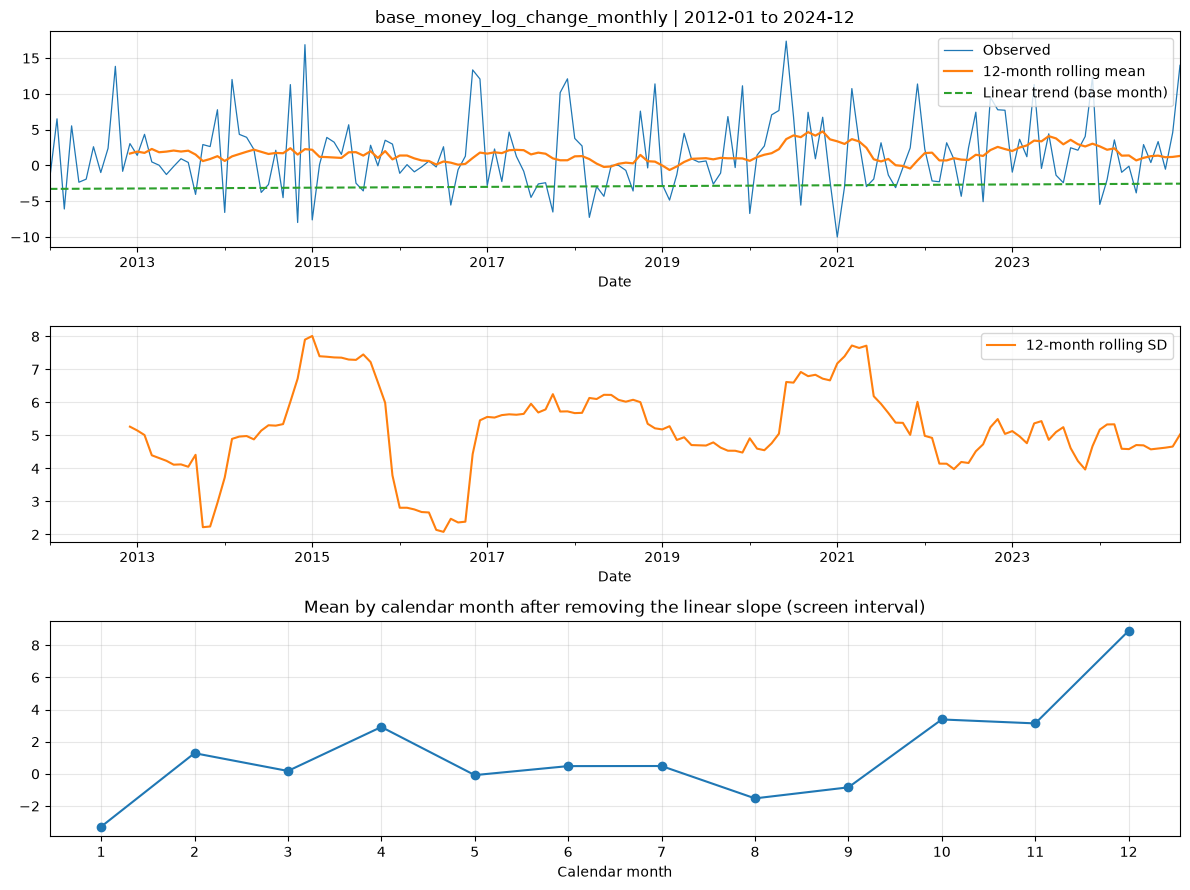


current_account_balance_annual_change_pp_monthly | training-period descriptive statistics
count    156.000000
mean       2.538462
std        6.957145
min       -7.700000
25%       -1.500000
50%        2.000000
75%        3.700000
max       18.800000
Name: current_account_balance_annual_change_pp_monthly, dtype: float64


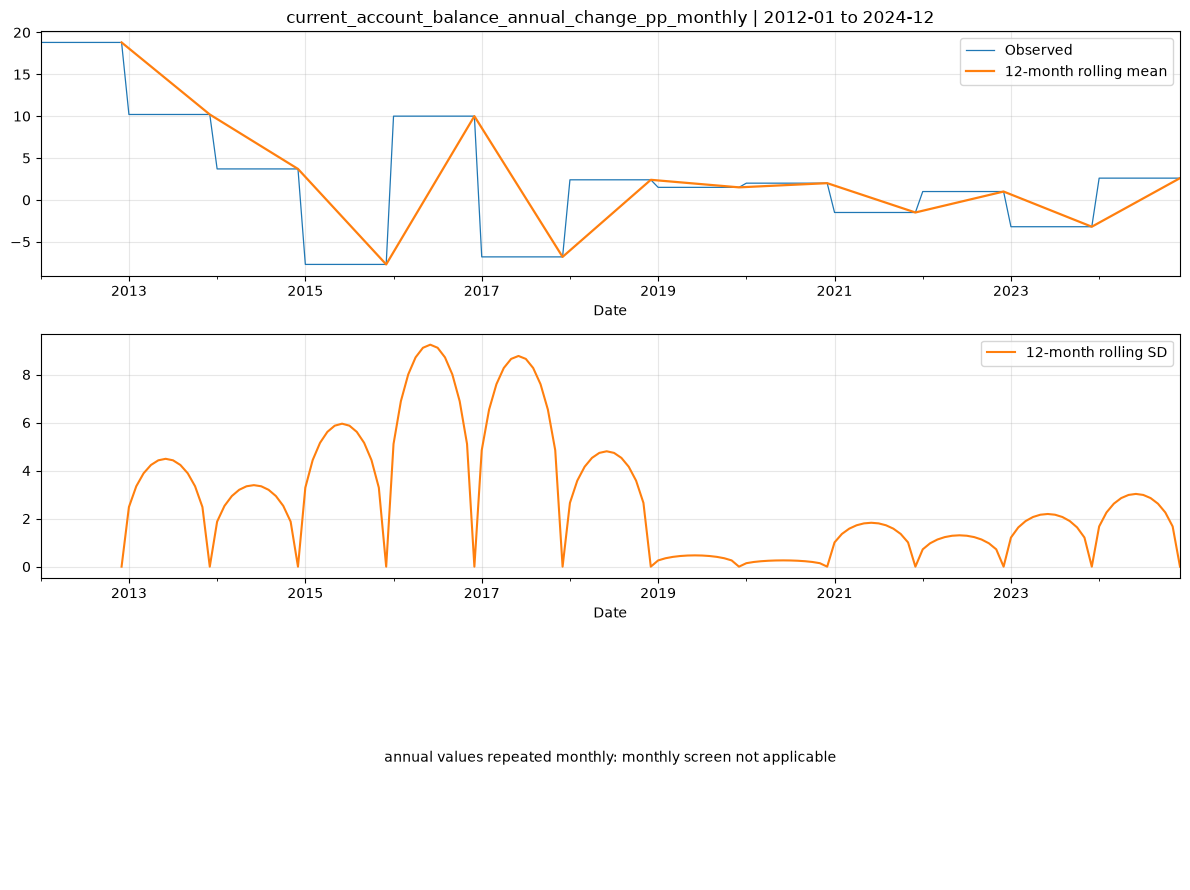


food_imports_log_change_monthly | training-period descriptive statistics
count    156.000000
mean       0.520339
std       71.333417
min     -180.363197
25%      -47.563796
50%        6.479607
75%       45.663243
max      207.508178
Name: food_imports_log_change_monthly, dtype: float64


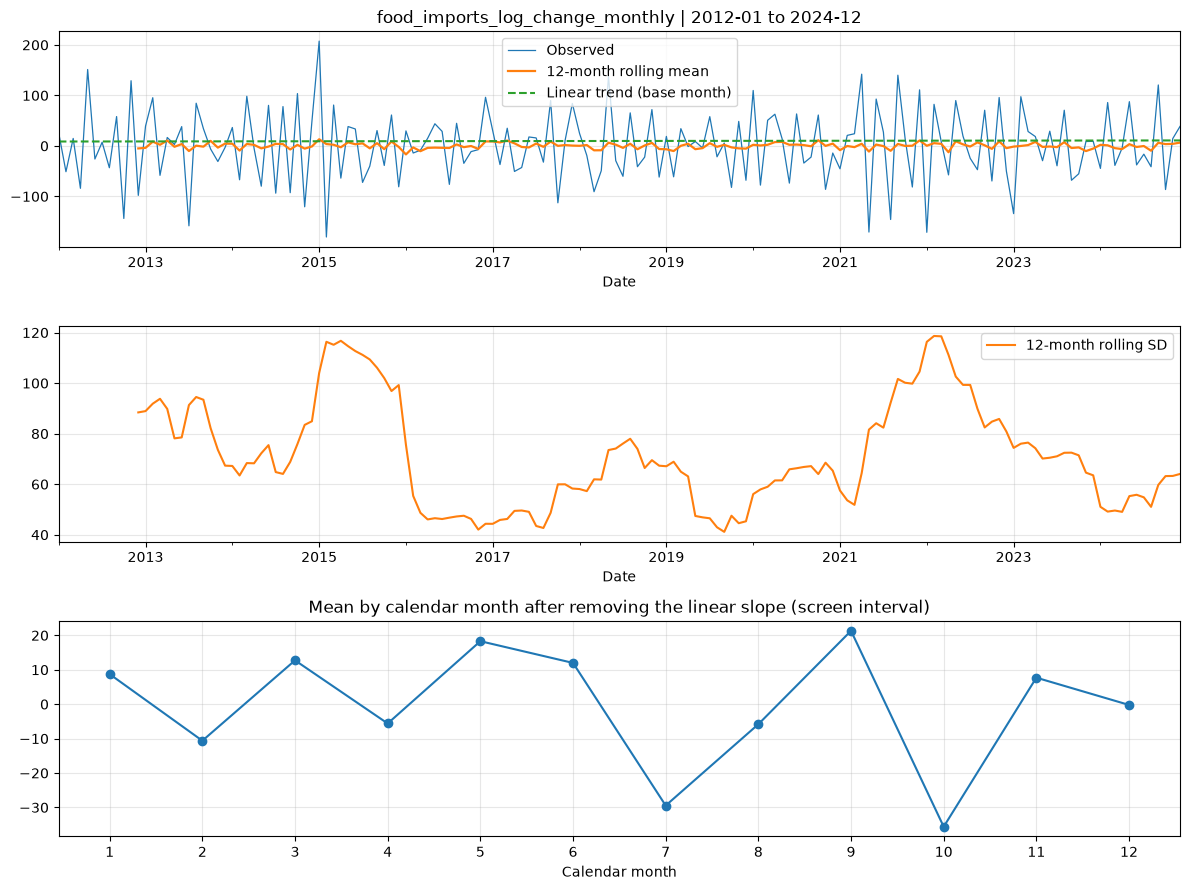


fuel_imports_log_change_monthly | training-period descriptive statistics
count    156.000000
mean       1.005853
std       81.610114
min     -400.012627
25%      -24.334700
50%        0.486679
75%       28.585092
max      416.902246
Name: fuel_imports_log_change_monthly, dtype: float64


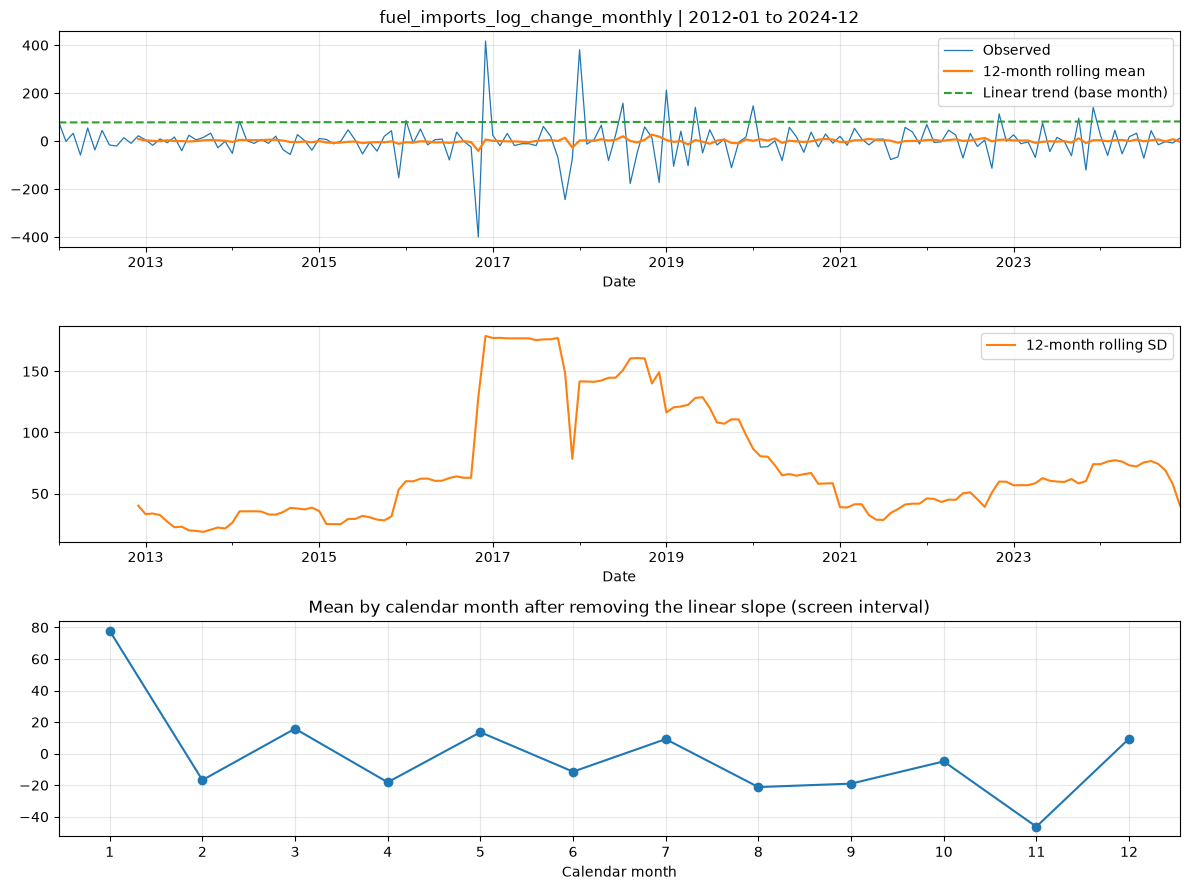


fx_reserves_log_change_monthly | training-period descriptive statistics
count    156.000000
mean      -0.008613
std        5.312093
min       -8.795792
25%       -2.877635
50%       -0.736422
75%        1.465043
max       32.054157
Name: fx_reserves_log_change_monthly, dtype: float64


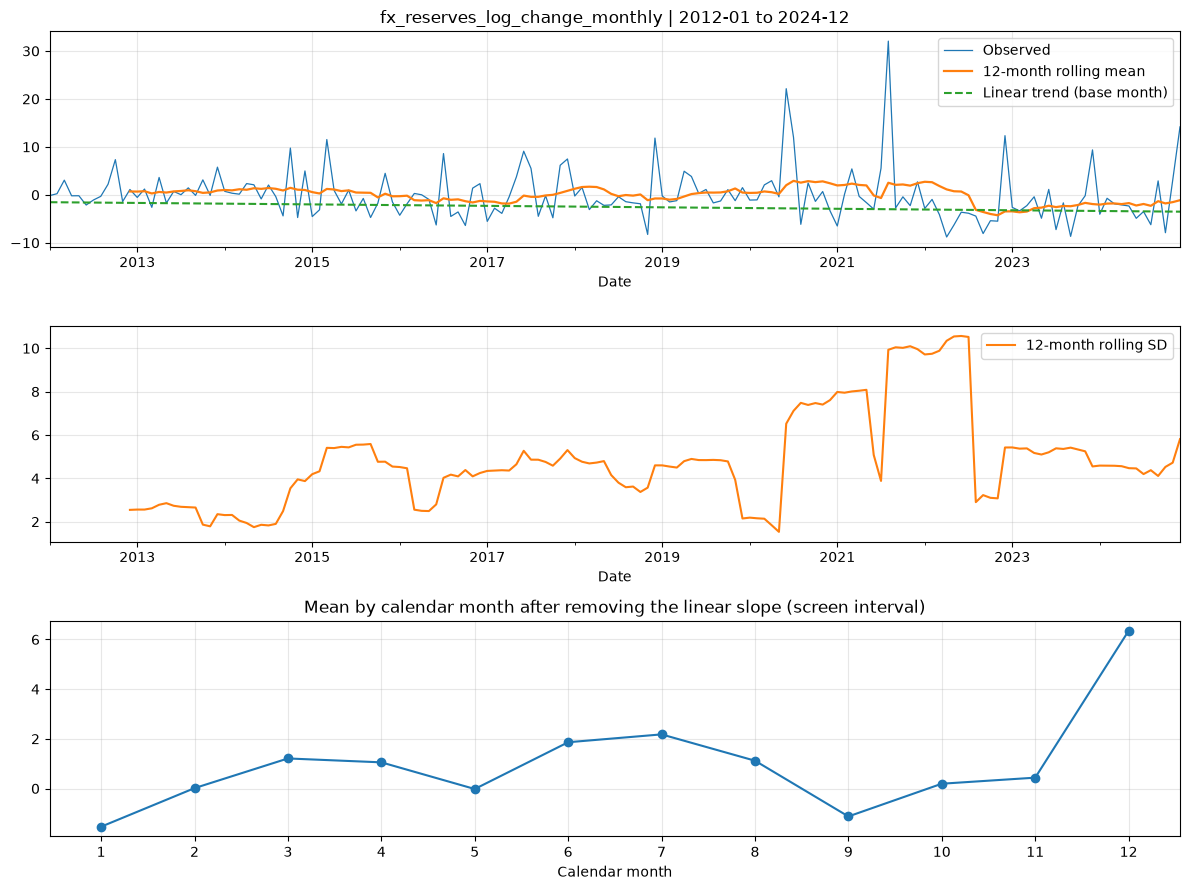


general_government_gross_debt_annual_change_pp_monthly | training-period descriptive statistics
count    156.000000
mean       1.607692
std        4.057483
min       -4.600000
25%       -1.700000
50%        1.100000
75%        4.500000
max       10.500000
Name: general_government_gross_debt_annual_change_pp_monthly, dtype: float64


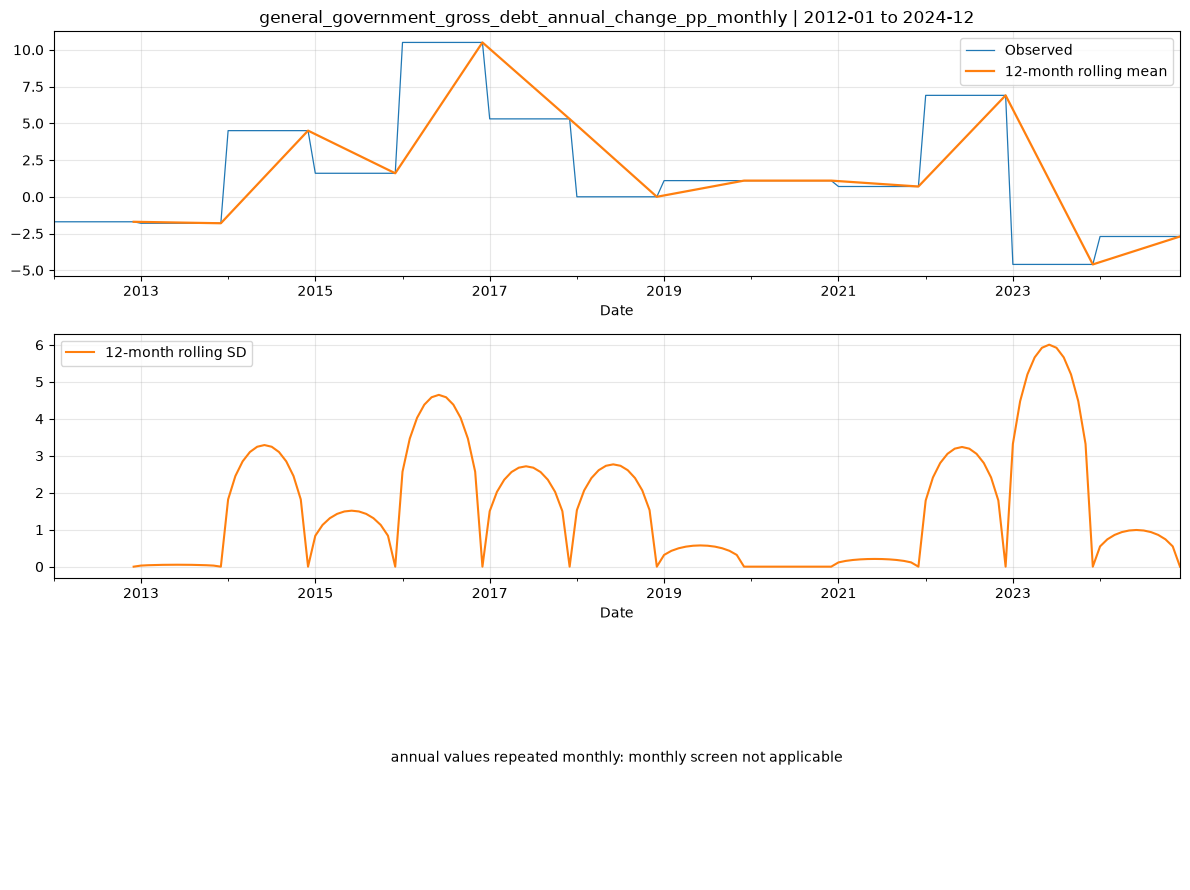


iron_ore_exports_log_change_monthly | training-period descriptive statistics
count    156.000000
mean       1.310248
std       58.041678
min     -259.538713
25%      -13.422823
50%        0.000000
75%       24.052960
max      212.520909
Name: iron_ore_exports_log_change_monthly, dtype: float64


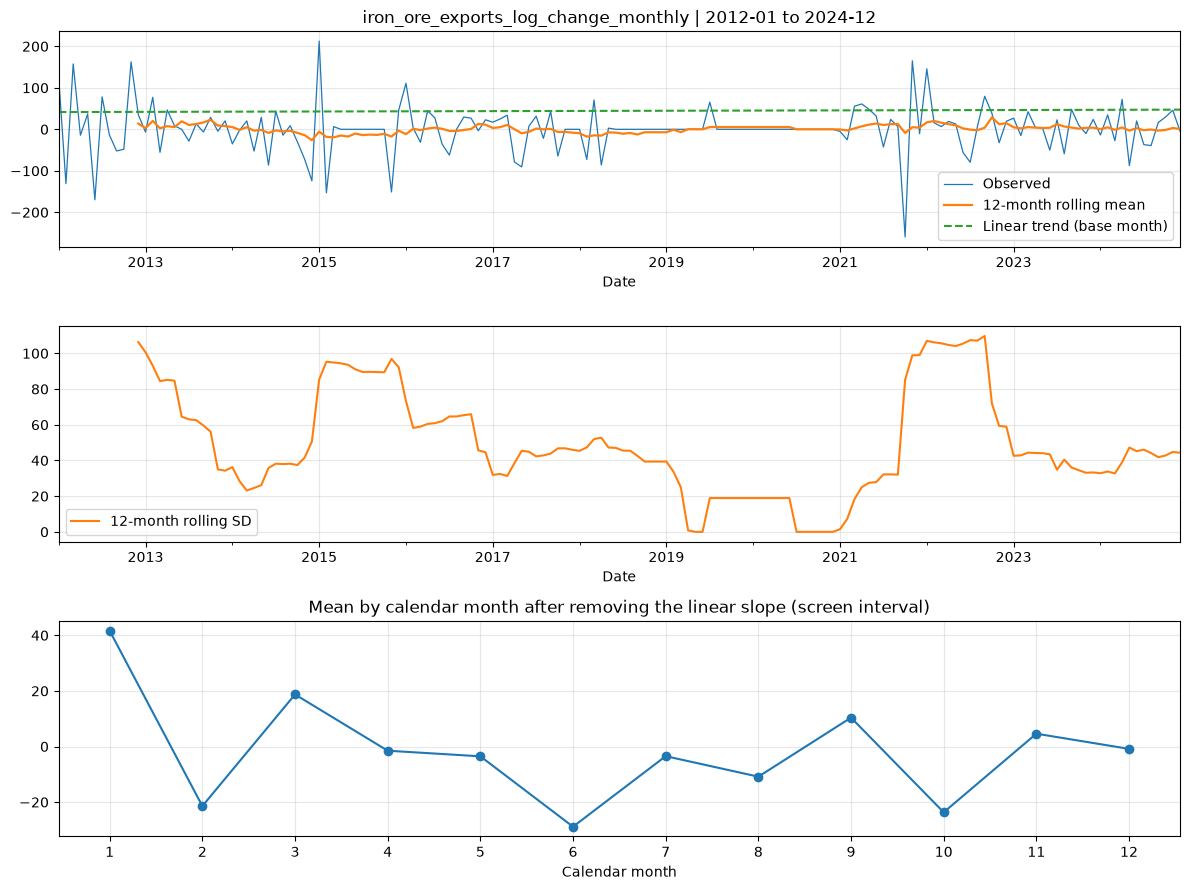


NO_FILL_iron_ore_exports_log_change_monthly | training-period descriptive statistics
count    124.000000
mean       1.160818
std       64.892041
min     -259.538713
25%      -29.015721
50%        2.936309
75%       29.563129
max      212.520909
Name: NO_FILL_iron_ore_exports_log_change_monthly, dtype: float64


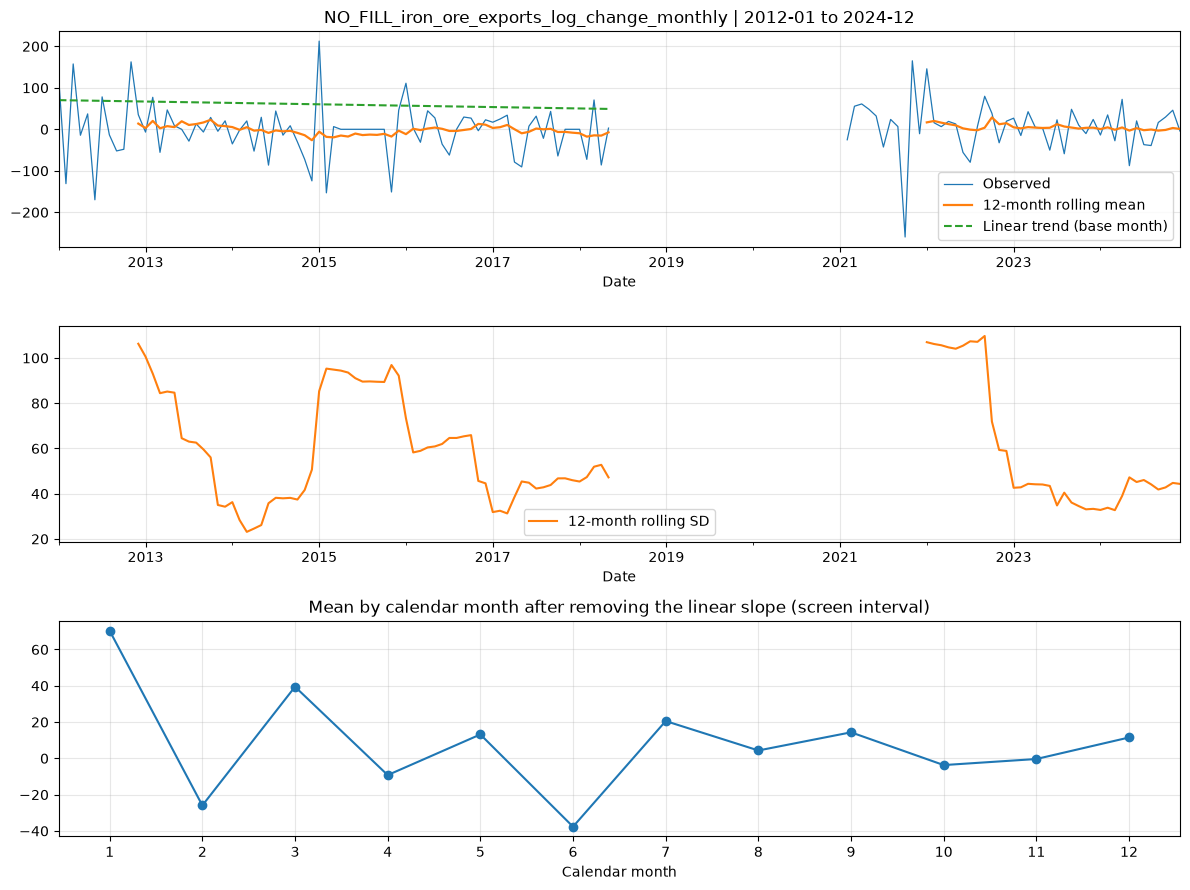


USDSLE_monthly | training-period descriptive statistics
count    156.000000
mean       1.066280
std        4.818423
min      -17.671220
25%       -0.057062
50%        0.184052
75%        1.267265
max       34.429449
Name: USDSLE_monthly, dtype: float64


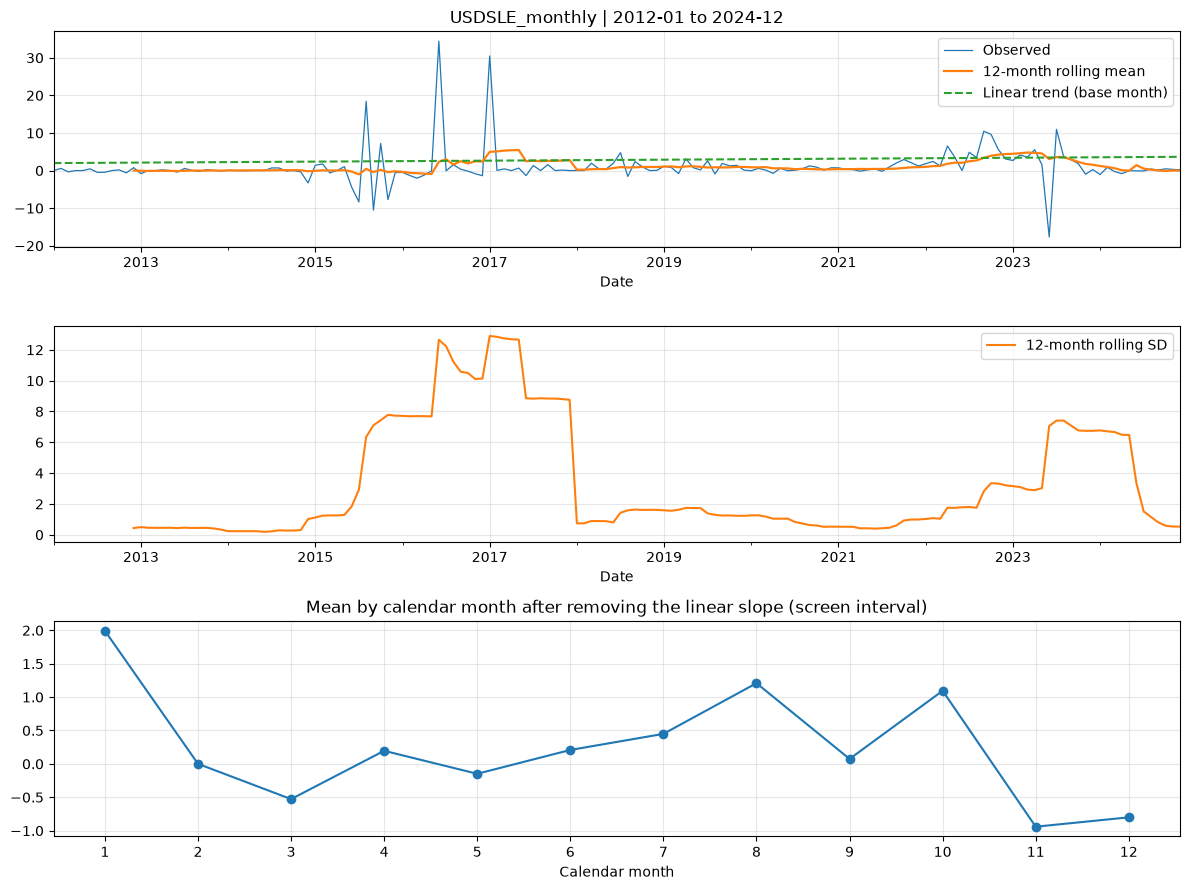

Displayed 9 figures: one CSV per figure, three diagnostic panels.


In [8]:
# One figure per CSV, with rolling and seasonal diagnostics in subplots.
plt.close("all")
plot_names = [
    name for name in dict.fromkeys(dataset_name_list)
    if name != "Sierra_Leone_Policy_Event_Dummies_monthly.csv"
]
screen_rows = []
rolling_statistics = {}
for dataset_name in plot_names:
    dataset_path = DATASET_PATH / dataset_name
    values = prepare_monthly(dataset_path)
    print(f"\n{dataset_path.stem} | training-period descriptive statistics")
    print(values.describe())
    annual_repeated = "_annual_change_pp_monthly" in dataset_path.stem
    row, rolling, segment, fitted = screen_series(values, annual_repeated)
    screen_rows.append(row)
    rolling_statistics[dataset_path.stem] = rolling
    plot_screen(values, row, rolling, segment, fitted)

print(f"Displayed {len(plot_names)} figures: one CSV per figure, three diagnostic panels.")


In [9]:
screening_results = pd.DataFrame(screen_rows)
# Holm correction across all trend + seasonal tests in this screen.
p_columns = ["trend_p", "seasonality_p"]
p_values = screening_results[p_columns].to_numpy(dtype=float)
finite = np.isfinite(p_values)
adjusted = np.full_like(p_values, np.nan)
if finite.any():
    adjusted[finite] = multipletests(p_values[finite], alpha=ALPHA, method="holm")[1]
screening_results[["trend_p_holm", "seasonality_p_holm"]] = adjusted


def interpret_screen(row):
    if row["applicability"] != "monthly":
        return pd.Series({"screen_pass": pd.NA, "screen_status": "not assessed", "next_step": row["applicability"]})
    if not np.isfinite(row["trend_p_holm"]) or not np.isfinite(row["seasonality_p_holm"]):
        return pd.Series({"screen_pass": pd.NA, "screen_status": "not assessed", "next_step": "inspect undefined test statistics"})
    signals = []
    if row["trend_p_holm"] < ALPHA:
        signals.append("linear trend")
    if row["seasonality_p_holm"] < ALPHA:
        signals.append("calendar-month seasonality")
    if row["mean_drift_score"] >= MEAN_DRIFT_LIMIT:
        signals.append("rolling mean drift")
    if row["std_ratio"] >= STD_RATIO_LIMIT:
        signals.append("rolling SD variation")
    if row["missing_months"]:
        signals.append("incomplete training interval")
    passed = not signals
    status = "no signal detected under this screen" if passed else "; ".join(signals)
    next_step = "proceed to ADF/KPSS; stationarity is NOT established" if passed else "review signals and choose ADF/KPSS sample and deterministic terms"
    return pd.Series({"screen_pass": passed, "screen_status": status, "next_step": next_step})

screening_results = pd.concat([screening_results, screening_results.apply(interpret_screen, axis=1)], axis=1)
screening_results["screen_pass"] = screening_results["screen_pass"].astype("boolean")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 90):
    display(screening_results)

ready_for_unit_root = screening_results.loc[screening_results["screen_pass"].fillna(False), "variable"].tolist()
needs_review = screening_results.loc[~screening_results["screen_pass"].fillna(False), "variable"].tolist()
print("No signals detected; proceed to unit-root testing:", ready_for_unit_root)
print("Review or use a separate frequency/sample before testing:", needs_review)
print("These are preliminary screens, not proof of stationarity or absence of structural breaks.")


,variable,valid_months,missing_months,screen_start,screen_end,screen_n,trend_per_year,trend_p,seasonality_p,mean_drift_score,std_ratio,applicability,sample_note,trend_p_holm,seasonality_p_holm,screen_pass,screen_status,next_step
0,base_money_log_change_monthly,156,0,2012-01-31,2024-12-31,156,0.056585,0.364603,2.139049e-25,0.540931,1.832506,monthly,full training interval,1.000000,2.994668e-24,False,calendar-month seasonality,review signals and choose ADF/KPSS sample and deterministic terms
1,current_account_balance_annual_change_pp_monthly,156,0,2012-01-31,2024-12-31,156,NaN,NaN,NaN,NaN,NaN,annual values repeated monthly: monthly screen not applicable,full training interval,NaN,NaN,<NA>,not assessed,annual values repeated monthly: monthly screen not applicable
2,food_imports_log_change_monthly,156,0,2012-01-31,2024-12-31,156,0.165156,0.711791,2.938181e-03,0.202409,2.199842,monthly,full training interval,1.000000,3.231999e-02,False,calendar-month seasonality; rolling SD variation,review signals and choose ADF/KPSS sample and deterministic terms
3,fuel_imports_log_change_monthly,156,0,2012-01-31,2024-12-31,156,0.307256,0.464314,1.098140e-03,0.163028,5.267308,monthly,full training interval,1.000000,1.317768e-02,False,calendar-month seasonality; rolling SD variation,review signals and choose ADF/KPSS sample and deterministic terms
4,fx_reserves_log_change_monthly,156,0,2012-01-31,2024-12-31,156,-0.152678,0.123027,4.416196e-13,0.807872,3.467967,monthly,full training interval,0.984213,5.741054e-12,False,calendar-month seasonality; rolling SD variation,review signals and choose ADF/KPSS sample and deterministic terms
5,general_government_gross_debt_annual_change_pp_monthly,156,0,2012-01-31,2024-12-31,156,NaN,NaN,NaN,NaN,NaN,annual values repeated monthly: monthly screen not applicable,full training interval,NaN,NaN,<NA>,not assessed,annual values repeated monthly: monthly screen not applicable
6,iron_ore_exports_log_change_monthly,156,0,2012-01-31,2024-12-31,156,0.446012,0.558824,2.712264e-01,0.410313,5.028576,monthly,full training interval,1.000000,1.000000e+00,False,rolling SD variation,review signals and choose ADF/KPSS sample and deterministic terms
7,NO_FILL_iron_ore_exports_log_change_monthly,124,32,2012-01-31,2018-05-31,77,-3.337542,0.064097,9.269858e-02,0.406442,2.796927,monthly,longest complete interval only; other months not assessed by tests,0.640965,8.342872e-01,False,rolling SD variation; incomplete training interval,review signals and choose ADF/KPSS sample and deterministic terms
8,USDSLE_monthly,156,0,2012-01-31,2024-12-31,156,0.128871,0.177722,2.218310e-01,0.743159,20.966062,monthly,full training interval,1.000000,1.000000e+00,False,rolling SD variation,review signals and choose ADF/KPSS sample and deterministic terms


No signals detected; proceed to unit-root testing: []
Review or use a separate frequency/sample before testing: ['base_money_log_change_monthly', 'current_account_balance_annual_change_pp_monthly', 'food_imports_log_change_monthly', 'fuel_imports_log_change_monthly', 'fx_reserves_log_change_monthly', 'general_government_gross_debt_annual_change_pp_monthly', 'iron_ore_exports_log_change_monthly', 'NO_FILL_iron_ore_exports_log_change_monthly', 'USDSLE_monthly']
These are preliminary screens, not proof of stationarity or absence of structural breaks.
